# SING versus GTM: paired 10D R-vine simulation study

Docker Command to Run:

docker run --rm --init \
  -v "$PWD:/workspace" -w /workspace \
  mhe_sing sh -c '
    pip install --no-cache-dir nbconvert ipykernel &&
    python -m nbconvert --to notebook --execute --inplace \
      --ExecutePreprocessor.kernel_name=python3 \
      --ExecutePreprocessor.timeout=-1 \
      sing_experiments/sing_gtm_comparison.ipynb
  '

Compare **SING degrees 2 and 3** with the paper's **GTM** across training sizes **125, 500, 2,000**, margins **Gaussian, exponential, Student's t (df 2.5)**, and **10 distinct vine/shuffle seeds**. There are 90 datasets, 180 SING runs, and 90 GTM runs. Each dataset has **20,000 independently simulated test observations** shared by the models.

No PIT or nonparanormal transform is used. Both models use training means and standard deviations; score matrices are restored to original variable labels. Reported likelihoods are joint log densities **on the original observation scale**, including the affine change-of-variables correction. Compare likelihoods within each marginal family.

GTM has three decorrelation layers with 10 basis functions on [-10, 10] and a marginal layer with 10 basis functions on [-5, 5]. Thirty seeded tuning trials select adaptive lasso and first/second difference penalties; marginal splines are unpenalized. Tuning uses an internal 80/20 split of N, including fold-specific standardization and adaptive weights. Penalties and iteration counts are selected before refitting the pilot and GTM on all N. The test set is used only for final scoring.

GTM's primary ranking score is the **mean absolute globally nuclear-normalized copula log-density Hessian**, matching the existing paper-study code. SING's primary score is its initial dense map's unthresholded mean squared Hessian, as in the single-run notebook; its final unthresholded scores are also saved. GTM has no binary threshold yet, so its precision/recall/F1/MCC are missing by design. SING retains its delta-method graph metrics. Missing/failed fits are displayed explicitly; paired differences use only successful runs on the same cached dataset.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'sing_experiments/simulation_common.py').exists())
sys.path.insert(0, str(ROOT))
from sing_experiments.simulation_common import (
    collect_results, paired_comparisons, read_json, select_cases,
)

RESULTS_DIR = ROOT / 'sing_experiments/results/sing_gtm_comparison'
RUN_LABEL = 'default'
GTM_SCORE = 'squared_hessian' # 'global_normalized_hessian'  # also 'squared_hessian' or 'pseudo_precision'
MODEL_ORDER = ['SING degree 2', 'SING degree 3', 'GTM']
COLORS = {'SING degree 2': '#2563eb', 'SING degree 3': '#7c3aed', 'GTM': '#dc2626'}


## Coverage and failures

The runners write one JSON result per fit and resume successful runs automatically. Re-run failed jobs after inspecting their `failure.txt` and `run.log`; they are retried rather than counted as successful. This notebook reads the JSON files directly, so concurrent jobs do not contend for a shared CSV.

In [2]:
results = collect_results(RESULTS_DIR, RUN_LABEL)
study_path = RESULTS_DIR / 'study.json'
study = read_json(study_path if study_path.exists() else ROOT / 'sing_experiments/simulation_study.json')
expected_models = [f'SING degree {degree}' for degree in study['sing_degrees']] + ['GTM']
expected = pd.DataFrame([
    dict(model=model, n_train=case.n_train, marginals=case.marginals, seed=case.seed)
    for case in select_cases(study) for model in expected_models
])
keys = ['model', 'n_train', 'marginals', 'seed']
if results.empty:
    completed = pd.DataFrame()
    coverage = expected.assign(status='not run')
    print('No fitted results yet. Run the scripts described in SIMULATION_STUDY.md, then rerun this notebook.')
else:
    if results.duplicated(keys).any():
        raise ValueError('Duplicate model/case rows; choose one RUN_LABEL.')
    gtm_mask = results.model.eq('GTM') & results.status.eq('ok')
    gtm_column = f'roc_auc_{GTM_SCORE}'
    if gtm_mask.any():
        if gtm_column not in results:
            raise ValueError(f'Saved GTM results have no {GTM_SCORE} score.')
        results.loc[gtm_mask, 'roc_auc'] = results.loc[gtm_mask, gtm_column]
    coverage = expected.merge(results[keys + ['status']], on=keys, how='left')
    coverage['status'] = coverage.status.fillna('not run')
    completed = results.loc[results.status.eq('ok')].copy()
    # Validate dataset pairing before aggregating results.
    paired_comparisons(results, 'roc_auc')
display(coverage.groupby(['model', 'status']).size().rename('runs').unstack(fill_value=0))
if not results.empty:
    failures = results.loc[results.status.isin(['failed', 'interrupted'])]
    if not failures.empty:
        display(failures.reindex(columns=keys + ['error', 'result_path']))


status,failed,not run,ok,running
model,,,,
GTM,0,0,90,0
SING degree 2,0,0,90,0
SING degree 3,15,74,0,1


,model,n_train,marginals,seed,error,result_path
180,SING degree 3,125,exp,1,FloatingPointError: Invalid delta-method varia...,/workspace/sing_experiments/results/sing_gtm_c...
181,SING degree 3,125,exp,2,FloatingPointError: Invalid delta-method varia...,/workspace/sing_experiments/results/sing_gtm_c...
182,SING degree 3,125,exp,3,RuntimeError: Transport-map optimization faile...,/workspace/sing_experiments/results/sing_gtm_c...
183,SING degree 3,125,exp,4,RuntimeError: Transport-map optimization faile...,/workspace/sing_experiments/results/sing_gtm_c...
184,SING degree 3,125,exp,5,FloatingPointError: Invalid delta-method varia...,/workspace/sing_experiments/results/sing_gtm_c...
186,SING degree 3,125,gauss,1,RuntimeError: Transport-map optimization faile...,/workspace/sing_experiments/results/sing_gtm_c...
187,SING degree 3,125,gauss,2,RuntimeError: Transport-map optimization faile...,/workspace/sing_experiments/results/sing_gtm_c...
188,SING degree 3,125,gauss,3,RuntimeError: Transport-map optimization faile...,/workspace/sing_experiments/results/sing_gtm_c...
189,SING degree 3,125,gauss,4,RuntimeError: Transport-map optimization faile...,/workspace/sing_experiments/results/sing_gtm_c...
190,SING degree 3,125,gauss,5,FloatingPointError: Invalid delta-method varia...,/workspace/sing_experiments/results/sing_gtm_c...


#### Take aways:

Its either maximum number of iterations reached e.g. set nit>150 or the computation of the variance (via the delta method) failed due to the fisher information. 

My thoughts: if we have less observations then we have degrees of freedom, e.g. here parameters as we dont have any penalization, then the fischer information may not be positive definite. This seems to be another limitation of the SING approach.

##### Sing Error output for degree 3:

FAILED SING degree 3: n125_gauss_seed01 (28.0s) — RuntimeError: Transport-map optimization failed: [{'message': 'Warning: Maximum number of iterations has been exceeded.', 'nit': 150, 'fval': np.float64(-2.3083958969522675)}]

FAILED SING degree 3: n125_gauss_seed02 (25.0s) — RuntimeError: Transport-map optimization failed: [{'message': 'Warning: Maximum number of iterations has been exceeded.', 'nit': 150, 'fval': np.float64(-2.6155269707885136)}]

FAILED SING degree 3: n125_gauss_seed03 (23.1s) — RuntimeError: Transport-map optimization failed: [{'message': 'Warning: Maximum number of iterations has been exceeded.', 'nit': 150, 'fval': np.float64(-2.235575850936429)}]

FAILED SING degree 3: n125_gauss_seed04 (31.3s) — RuntimeError: Transport-map optimization failed: [{'message': 'Warning: Maximum number of iterations has been exceeded.', 'nit': 150, 'fval': np.float64(-2.625207274731118)}]

^[[A^[[AFAILED SING degree 3: n125_gauss_seed05 (10529.5s) — FloatingPointError: Invalid delta-method variance; inspect map fit/Fisher information
FAILED SING degree 3: n125_gauss_seed06 (11516.6s) — FloatingPointError: Invalid delta-method variance; inspect map fit/Fisher information

FAILED SING degree 3: n125_gauss_seed07 (34.3s) — RuntimeError: Transport-map optimization failed: [{'message': 'Warning: Maximum number of iterations has been exceeded.', 'nit': 150, 'fval': np.float64(-3.2655509967490546)}]

FAILED SING degree 3: n125_gauss_seed08 (48.6s) — RuntimeError: Transport-map optimization failed: [{'message': 'Warning: Maximum number of iterations has been exceeded.', 'nit': 150, 'fval': np.float64(-2.7506999237528165)}]

FAILED SING degree 3: n125_gauss_seed09 (26.8s) — RuntimeError: Transport-map optimization failed: [{'message': "Warning: CG iterations didn't converge. The Hessian is not positive definite.", 'nit': 83, 'fval': np.float64(-1.3848404940634533)}]

FAILED SING degree 3: n125_gauss_seed10 (11575.5s) — FloatingPointError: Invalid delta-method variance; inspect map fit/Fisher information

FAILED SING degree 3: n125_exp_seed01 (11763.1s) — FloatingPointError: Invalid delta-method variance; inspect map fit/Fisher information

FAILED SING degree 3: n125_exp_seed02 (10114.8s) — FloatingPointError: Invalid delta-method variance; inspect map fit/Fisher information

FAILED SING degree 3: n125_exp_seed03 (25.7s) — RuntimeError: Transport-map optimization failed: [{'message': 'Warning: Maximum number of iterations has been exceeded.', 'nit': 150, 'fval': np.float64(-2.3227862803739914)}, {'message': 'Warning: Maximum number of iterations has been exceeded.', 'nit': 150, 'fval': np.float64(-3.081237214971617)}]

FAILED SING degree 3: n125_exp_seed04 (33.5s) — RuntimeError: Transport-map optimization failed: [{'message': 'Warning: Maximum number of iterations has been exceeded.', 'nit': 150, 'fval': np.float64(-3.2027544272829003)}]

FAILED SING degree 3: n125_exp_seed05 (9883.4s) — FloatingPointError: Invalid delta-method variance; inspect map fit/Fisher information

## ROC-AUC and test log likelihood

Lines show the mean across successful seeds; error bars show **one standard error across seeds**. Faint points show individual runs. Counts are shown in the summary table. These panels use all successful fits per model; the paired comparison below restricts to matched seeds.

In [3]:
if not completed.empty:
    summary = completed.groupby(['marginals', 'n_train', 'model']).agg(
        n_runs=('roc_auc', 'count'),
        roc_auc_mean=('roc_auc', 'mean'), roc_auc_sd=('roc_auc', 'std'),
        test_loglik_mean=('test_loglik_mean', 'mean'), test_loglik_sd=('test_loglik_mean', 'std'),
        train_loglik_mean=('train_loglik_mean', 'mean'),
    ).reset_index()
    display(summary)
else:
    summary = pd.DataFrame()


,marginals,n_train,model,n_runs,roc_auc_mean,roc_auc_sd,test_loglik_mean,test_loglik_sd,train_loglik_mean
0,exp,125,GTM,10,0.903571,0.043522,-8.393946,0.507981,-6.935345
1,exp,125,SING degree 2,10,0.747421,0.139527,-13.359176,0.283481,-12.563115
2,exp,500,GTM,10,0.984127,0.013873,-7.363861,0.349909,-6.826580
3,exp,500,SING degree 2,10,0.913889,0.049574,-10.420303,0.642693,-9.518912
4,exp,2000,GTM,10,0.990675,0.009449,-6.943733,0.361760,-6.747729
5,exp,2000,SING degree 2,10,0.938492,0.034366,-9.604639,0.434201,-9.303037
6,gauss,125,GTM,10,0.930556,0.027269,-11.021692,0.263341,-9.723667
7,gauss,125,SING degree 2,10,0.877778,0.064097,-13.336332,0.496935,-12.634259
8,gauss,500,GTM,10,0.980556,0.019503,-10.369960,0.338557,-9.746658
9,gauss,500,SING degree 2,10,0.983135,0.013335,-10.626127,0.343645,-9.985680


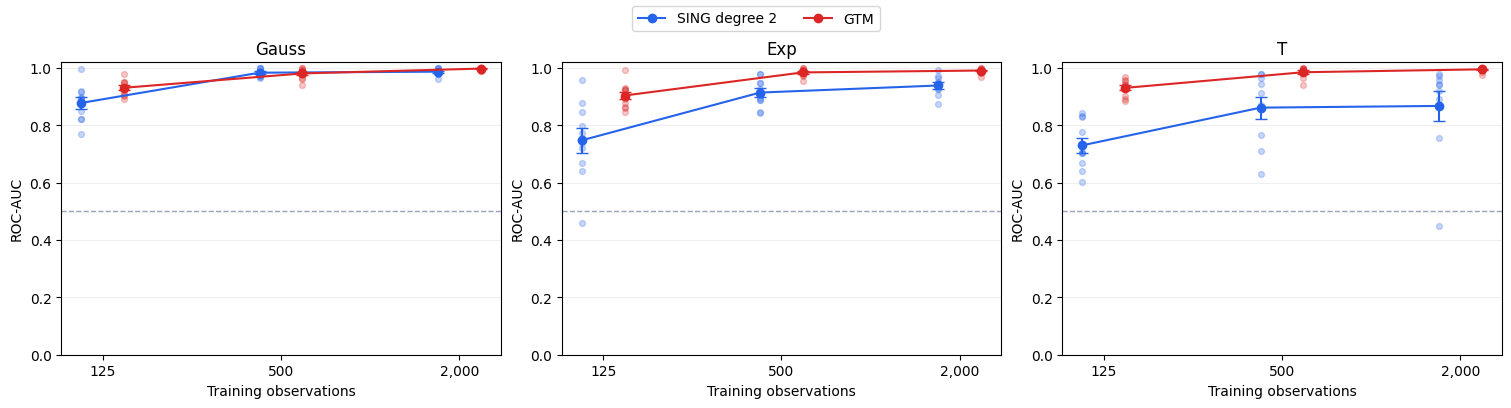

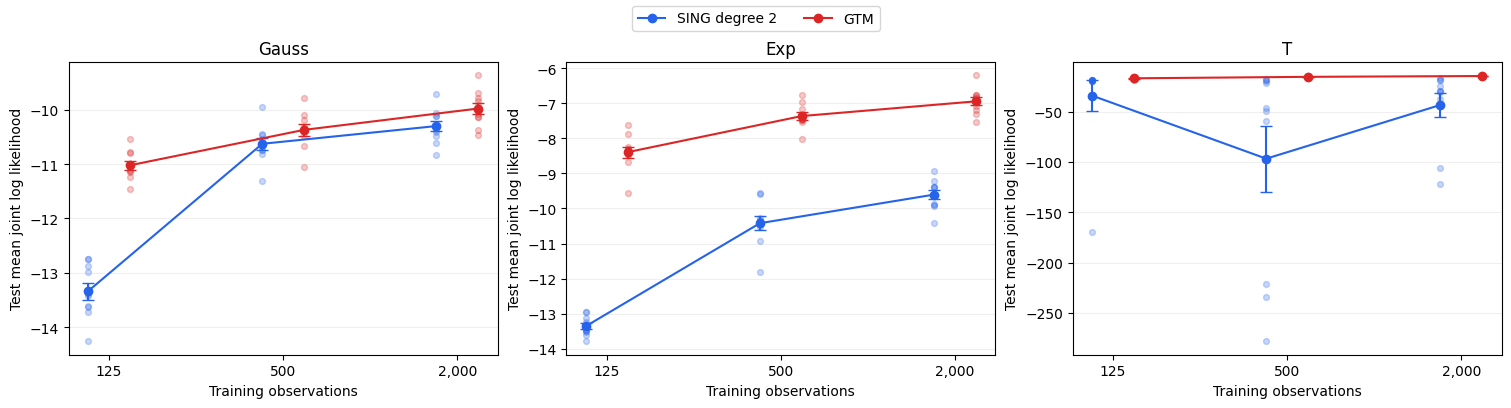

In [4]:
def plot_metric(metric, label, limits=None):
    if completed.empty:
        print(f'{label}: waiting for completed fits.')
        return
    families = study['marginals']
    sizes = study['train_sizes']
    fig, axes = plt.subplots(1, len(families), figsize=(5 * len(families), 4), squeeze=False,
                             constrained_layout=True)
    for ax, family in zip(axes[0], families):
        for offset, model in zip([-0.12, 0.0, 0.12], MODEL_ORDER):
            subset = completed.loc[completed.marginals.eq(family) & completed.model.eq(model)]
            if subset.empty:
                continue
            stats = subset.groupby('n_train')[metric].agg(['mean', 'std', 'count']).reindex(sizes)
            positions = np.arange(len(sizes)) + offset
            for j, size in enumerate(sizes):
                values = subset.loc[subset.n_train.eq(size), metric].to_numpy()
                ax.scatter(np.full(len(values), positions[j]), values, color=COLORS[model], alpha=0.25, s=18)
            ax.plot(positions, stats['mean'], marker='o', color=COLORS[model], label=model)
            uncertainty = stats['std'] / np.sqrt(stats['count'])
            valid = np.isfinite(uncertainty.to_numpy())
            if valid.any():
                ax.errorbar(positions[valid], stats['mean'].to_numpy()[valid],
                            yerr=uncertainty.to_numpy()[valid], fmt='none', capsize=4, color=COLORS[model])
        ax.set(xticks=np.arange(len(sizes)), xticklabels=[f'{n:,}' for n in sizes],
               xlabel='Training observations', ylabel=label, title=family.capitalize())
        if limits is not None:
            ax.set_ylim(*limits)
        if metric == 'roc_auc':
            ax.axhline(0.5, color='#94a3b8', linestyle='--', linewidth=1)
        ax.grid(axis='y', alpha=0.2)
    legend = {}
    for ax in axes[0]:
        handles, labels = ax.get_legend_handles_labels()
        legend.update(zip(labels, handles))
    if legend:
        fig.legend(list(legend.values()), list(legend), loc='outside upper center', ncol=3)
    plt.show()

plot_metric('roc_auc', 'ROC-AUC', limits=(0, 1.02))
plot_metric('test_loglik_mean', 'Test mean joint log likelihood')


## Paired comparisons

Positive differences favor GTM. `n_pairs` counts seeds with a successful GTM and the corresponding successful SING fit on the identical data. Standard errors describe variability across these paired seeds; no missing result is replaced by a favorable score.

In [5]:
paired_auc = paired_comparisons(results, 'roc_auc')
paired_loglik = paired_comparisons(results, 'test_loglik_mean')
paired = pd.concat([paired_auc, paired_loglik], ignore_index=True)
if not paired.empty:
    display(paired)
else:
    print('No complete GTM/SING pairs yet.')


,n_train,marginals,comparison,metric,n_pairs,mean_difference,sd_difference,se_difference
0,125,exp,GTM minus SING degree 2,roc_auc,10,0.156151,0.138312,0.043738
1,125,gauss,GTM minus SING degree 2,roc_auc,10,0.052778,0.064654,0.020445
2,125,t,GTM minus SING degree 2,roc_auc,10,0.200198,0.074501,0.023559
3,500,exp,GTM minus SING degree 2,roc_auc,10,0.070238,0.049495,0.015652
4,500,gauss,GTM minus SING degree 2,roc_auc,10,-0.002579,0.017525,0.005542
5,500,t,GTM minus SING degree 2,roc_auc,10,0.123413,0.114907,0.036337
6,2000,exp,GTM minus SING degree 2,roc_auc,10,0.052183,0.033175,0.010491
7,2000,gauss,GTM minus SING degree 2,roc_auc,10,0.010714,0.009729,0.003077
8,2000,t,GTM minus SING degree 2,roc_auc,10,0.127579,0.162464,0.051376
9,125,exp,GTM minus SING degree 2,test_loglik_mean,10,4.965230,0.559364,0.176886


## Paired differences by seed: boxplots

Each figure compares GTM with SING degrees 2 and 3 in separate panels. The x axis is training sample size; colors identify exponential (`exp`), Gaussian (`gauss`), and Student's t (`t`) margins in a shared legend. Each point is one matched seed, and each box summarizes those paired differences (median, quartiles, and whiskers extending to the most extreme observations within 1.5 IQR). Positive values favor GTM. Only successful fits on identical cached datasets are paired; missing or nonfinite scores are omitted.

The three ROC-AUC figures use GTM's `global_normalized_hessian`, `squared_hessian`, and `pseudo_precision` scores, respectively, against SING's initial dense-map ROC-AUC. They are independent of the earlier `GTM_SCORE` selection. Test mean joint log likelihood has one figure because it does not depend on the ranking score. Likelihood differences retain the original observation scale; compare them within each marginal family.

The likelihood-difference y axis uses a symmetric logarithmic scale to retain both signs and zero, with a linear region between −0.01 and 0.01. ROC-AUC differences retain a linear scale.


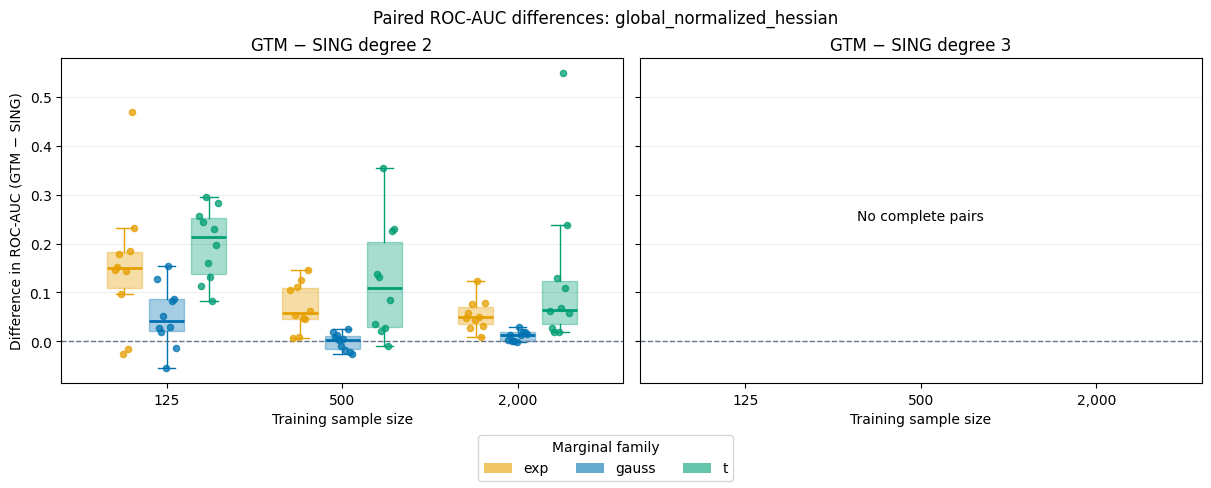

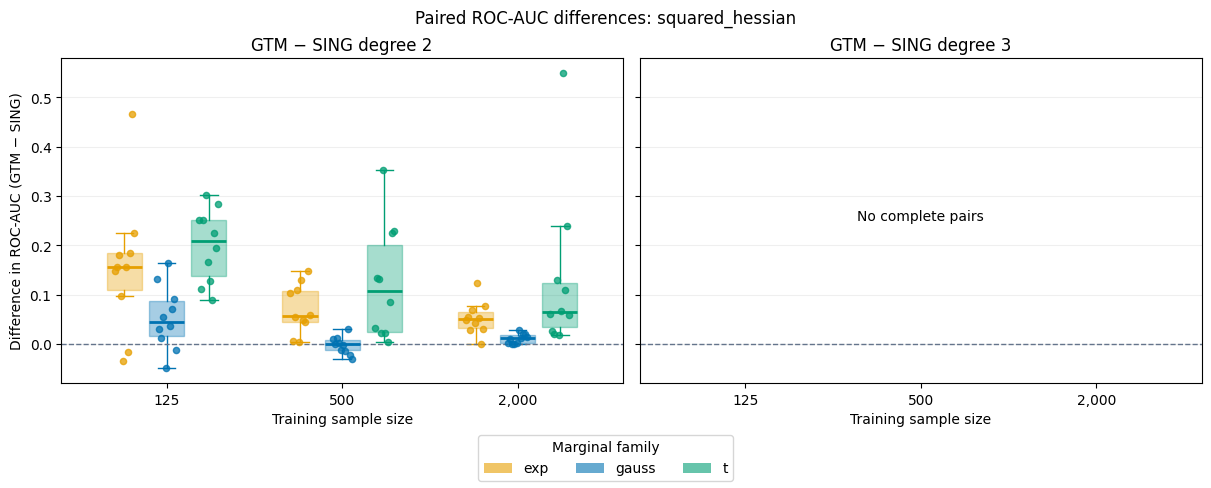

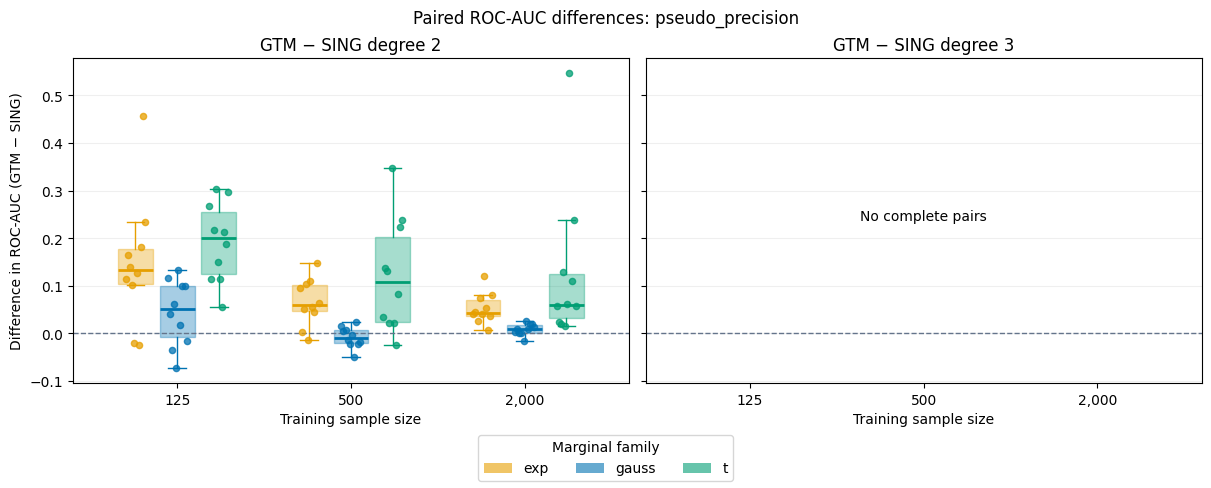

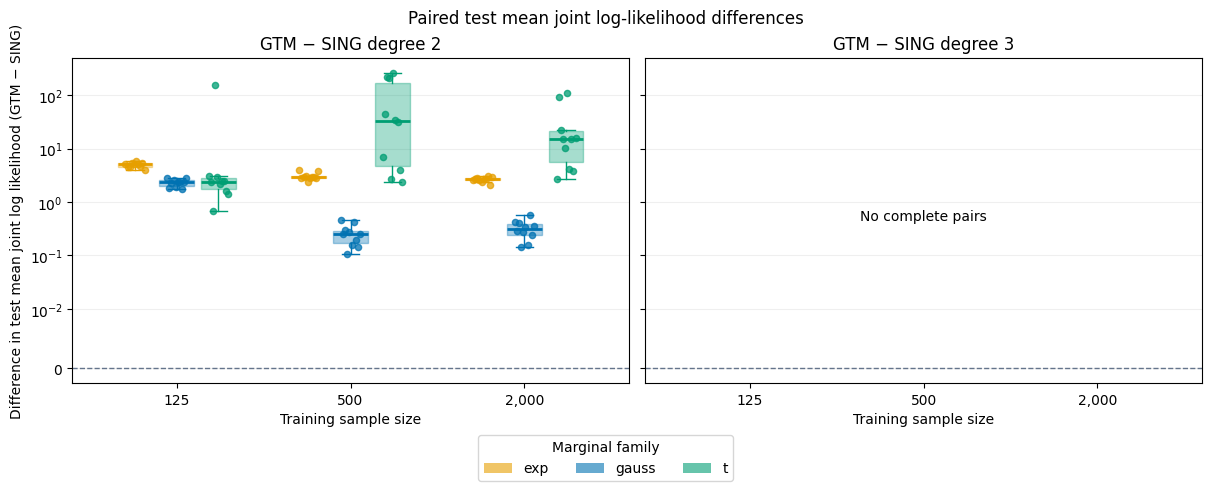

In [6]:
from matplotlib.patches import Patch

GTM_AUC_SCORES = ['global_normalized_hessian', 'squared_hessian', 'pseudo_precision']
MARGINAL_COLORS = {'exp': '#e69f00', 'gauss': '#0072b2', 't': '#009e73'}


def seed_differences(metric, gtm_score=None):
    """Pair individual successful seeds, preserving dataset identity checks."""
    columns = ['n_train', 'marginals', 'seed', 'sing_model', 'difference']
    if results.empty:
        return pd.DataFrame(columns=columns)
    good = results.loc[results.status.eq('ok')].copy()
    if good.empty:
        return pd.DataFrame(columns=columns)
    if gtm_score is not None:
        score_column = f'roc_auc_{gtm_score}'
        if score_column not in good:
            print(f'No saved {score_column} values; no pairs available for this score.')
            return pd.DataFrame(columns=columns)
        mask = good.model.eq('GTM')
        good.loc[mask, metric] = good.loc[mask, score_column]
    # Reject duplicate fits and mismatched cached datasets before pairing.
    paired_comparisons(good, metric)
    table = good.pivot(index=['n_train', 'marginals', 'seed'], columns='model', values=metric)
    if 'GTM' not in table:
        return pd.DataFrame(columns=columns)
    differences = []
    for degree in study['sing_degrees']:
        model = f'SING degree {degree}'
        if model not in table:
            continue
        pairs = table[['GTM', model]].replace([np.inf, -np.inf], np.nan).dropna()
        rows = (pairs['GTM'] - pairs[model]).rename('difference').reset_index()
        rows['sing_model'] = model
        differences.append(rows)
    return pd.concat(differences, ignore_index=True) if differences else pd.DataFrame(columns=columns)


def plot_seed_difference_boxes(differences, label, title, yscale='linear'):
    if differences.empty:
        print(f'{title}: waiting for complete GTM/SING pairs.')
        return
    families = [family for family in ['exp', 'gauss', 't'] if family in study['marginals']]
    sizes = study['train_sizes']
    models = [f'SING degree {degree}' for degree in study['sing_degrees']]
    fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 4.8),
                             squeeze=False, sharey=True, constrained_layout=True)
    offsets = (np.arange(len(families)) - (len(families) - 1) / 2) * 0.24
    for ax, model in zip(axes[0], models):
        subset = differences.loc[differences.sing_model.eq(model)]
        for offset, family in zip(offsets, families):
            for j, size in enumerate(sizes):
                values = subset.loc[subset.marginals.eq(family) & subset.n_train.eq(size)]
                values = values.sort_values('seed')['difference'].to_numpy()
                if len(values) == 0:
                    continue
                position = j + offset
                color = MARGINAL_COLORS[family]
                ax.boxplot([values], positions=[position], widths=0.20, patch_artist=True,
                           manage_ticks=False, showfliers=False,
                           boxprops={'facecolor': color, 'edgecolor': color, 'alpha': 0.35},
                           medianprops={'color': color, 'linewidth': 2},
                           whiskerprops={'color': color}, capprops={'color': color})
                # One point per paired seed, including outliers; deterministic offsets.
                jitter = np.linspace(-0.055, 0.055, len(values)) if len(values) > 1 else np.zeros(1)
                ax.scatter(position + jitter, values, color=color, s=20, alpha=0.75, zorder=3)
        if yscale == 'symlog':
            ax.set_yscale('symlog', linthresh=0.01)
        else:
            ax.set_yscale(yscale)
        ax.axhline(0, color='#64748b', linestyle='--', linewidth=1)
        ax.set(xticks=np.arange(len(sizes)), xticklabels=[f'{n:,}' for n in sizes],
               xlabel='Training sample size', title=f'GTM − {model}',
               xlim=(-0.6, len(sizes) - 0.4))
        ax.grid(axis='y', alpha=0.2)
        if subset.empty:
            ax.text(0.5, 0.5, 'No complete pairs', ha='center', transform=ax.transAxes)
    axes[0, 0].set_ylabel(label)
    fig.suptitle(title)
    fig.legend(handles=[Patch(facecolor=MARGINAL_COLORS[f], label=f, alpha=0.6) for f in families],
               title='Marginal family', loc='outside lower center', ncol=len(families))
    plt.show()


# Each GTM AUC variant is compared with the same initial-dense SING AUC.
# These plots are independent of GTM_SCORE used in the earlier panels.
auc_seed_differences = {}
for score in GTM_AUC_SCORES:
    differences = seed_differences('roc_auc', gtm_score=score)
    auc_seed_differences[score] = differences
    plot_seed_difference_boxes(differences, 'Difference in ROC-AUC (GTM − SING)',
                               f'Paired ROC-AUC differences: {score}')

loglik_seed_differences = seed_differences('test_loglik_mean')
plot_seed_difference_boxes(loglik_seed_differences,
                           'Difference in test mean joint log likelihood (GTM − SING)',
                           'Paired test mean joint log-likelihood differences', yscale='symlog')


## Other stored metrics and exports

Train and test likelihoods are saved as sums and means, along with per-observation log densities. Thresholded SING metrics use the final SING graph, and ranking scores use the initial dense fit. GTM ranking matrices are available in each run's `evaluation.npz`, including global normalized Hessians, squared Hessians, absolute Hessians, and pseudo-precision. GTM binary graph metrics remain undefined until a thresholding rule is chosen independently of the ground-truth labels.

In [7]:
if not completed.empty:
    display(completed.reindex(columns=keys + [
        'roc_auc', 'precision', 'recall', 'f1', 'mcc',
        'train_loglik_mean', 'test_loglik_mean', 'train_loglik_sum', 'test_loglik_sum',
        'device', 'fit_seconds', 'threshold_method',
    ]).sort_values(keys))
    results.to_csv(RESULTS_DIR / f'metrics_{RUN_LABEL}.csv', index=False)
    summary.to_csv(RESULTS_DIR / f'summary_{RUN_LABEL}.csv', index=False)
    paired.to_csv(RESULTS_DIR / f'paired_comparisons_{RUN_LABEL}.csv', index=False)
    print('Exported metric, summary, and paired-comparison CSVs to', RESULTS_DIR)


,model,n_train,marginals,seed,roc_auc,precision,recall,f1,mcc,train_loglik_mean,test_loglik_mean,train_loglik_sum,test_loglik_sum,device,fit_seconds,threshold_method
0,GTM,125,exp,1,0.992063,NaN,NaN,NaN,NaN,-6.595273,-8.244242,-824.409111,-1.648848e+05,cuda,52.510961,deferred
1,GTM,125,exp,2,0.878968,NaN,NaN,NaN,NaN,-7.294600,-8.668246,-911.824986,-1.733649e+05,cuda,50.838353,deferred
2,GTM,125,exp,3,0.847222,NaN,NaN,NaN,NaN,-6.728434,-8.443217,-841.054295,-1.688643e+05,cuda,42.217525,deferred
3,GTM,125,exp,4,0.892857,NaN,NaN,NaN,NaN,-5.860100,-8.418757,-732.512517,-1.683751e+05,cuda,57.303539,deferred
4,GTM,125,exp,5,0.922619,NaN,NaN,NaN,NaN,-6.477223,-7.877680,-809.652901,-1.575536e+05,cuda,52.722097,deferred
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,SING degree 2,2000,t,6,0.918651,0.656250,0.875000,0.750000,0.386555,-14.379027,-121.883551,-28758.053266,-2.437671e+06,cpu,2670.116004,SING_delta_method
146,SING degree 2,2000,t,7,0.448413,0.000000,0.000000,0.000000,0.000000,-18.496469,-18.652036,-36992.938527,-3.730407e+05,cpu,1523.457259,SING_delta_method
147,SING degree 2,2000,t,8,0.890873,0.785714,0.916667,0.846154,0.649245,-15.654090,-29.203724,-31308.179033,-5.840745e+05,cpu,1808.800992,SING_delta_method
148,SING degree 2,2000,t,9,0.753968,1.000000,0.041667,0.080000,0.141019,-18.595663,-18.685103,-37191.326445,-3.737021e+05,cpu,1660.961753,SING_delta_method


Exported metric, summary, and paired-comparison CSVs to /workspace/sing_experiments/results/sing_gtm_comparison
